## Interpretable Basis Decomposition (IBD): iNat Bees

In [1]:
!pwd
import sys, os
sys.path.append('./wingbeats/')

/mnt/KInsektDaten/teo


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import glob, pickle, cv2
from sklearn.metrics import label_ranking_average_precision_score as lrap
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import log_loss
from sklearn.metrics.pairwise import cosine_similarity
from tensorflow.keras.layers.experimental.preprocessing import Rescaling

from beexplainable.beexplainable.modelling import classifiers as cls
from beexplainable.beexplainable.preprocessing import parsers as ps
from beexplainable.beexplainable.utils import metafile_readers as mr
from wingbeats import modelling as wm # for building simple classifiers

No module named 'nltk'


In [3]:
import tensorflow as tf
print(tf.__version__)

# Select GPU
print(tf.test.gpu_device_name())

gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs available:", len(gpus))
try:
    tf.config.experimental.set_memory_growth(gpus[0], True) # don't allocate whole memory
except RuntimeError as e:
    print(e) # 'Invalid device or cannot modify virtual devices once initialized.'

2.8.1
/device:GPU:0
Num GPUs available: 1


2024-03-14 19:46:15.383687: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-03-14 19:46:15.954276: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /device:GPU:0 with 47119 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [4]:
spec_subfolder = '5_species/'
metafolder = './beexplainable/metafiles/Bees_Christian/'
CONCEPTS_PATH = '../data/Wildbienen/Concepts_Bombus_vs_Andrena_StabDiff_insects/'
CLASSES_PATH = metafolder + spec_subfolder + '/classes.txt'
BEES_PATH = '../data/Wildbienen/Bees_Christian_masked_bbox/Whole/'

IMAGES_PATH = metafolder + 'images_5.txt'
IMAGES_LABELS_PATH = metafolder + spec_subfolder + 'image_class_labels.txt'
MODELS_PATH  = './beexplainable/models/'

### Load Test Images

In [5]:
batch_size = 64
img_height = img_width = 224

In [6]:
# Read file IDs and corresponding class labels
img_dict = mr.metafile_to_dict(IMAGES_PATH)
img_label_dict = mr.metafile_to_dict(IMAGES_LABELS_PATH)
file_ids_bees = list( img_dict.keys() )
y_true_bees   = list( img_label_dict.values() )
y_true_bees   = np.asarray(y_true_bees, dtype = np.uint8) - 1
# Note! Labels in CUB format start at index 1, but cross entropy needs to start at 0
len(y_true_bees)

216

In [7]:
classes = list( mr.metafile_to_dict(CLASSES_PATH).values() )
classes

['Andrena_bicolor',
 'Andrena_flavipes',
 'Andrena_fulva',
 'Bombus_lucorum',
 'Bombus_pratorum']

In [8]:
# Get dictionary of file IDs and file names
# Convert it into a tf.StaticHashTable to be able to retrieve dictionary values during eager execution
# Alternative: tf.gather
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids_bees, list(img_dict.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, BEES_PATH),
                                          label)

2024-03-14 19:46:16.025347: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 47119 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [9]:
# Conversion to tf.Dataset
train_val_set = ps.parse_to_dataset(file_ids_bees, y_true_bees, parse_image_lab)
train_val_set = train_val_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images
normalization_layer = Rescaling(1./255)
train_val_set = train_val_set.map(lambda x, y: (normalization_layer(x), y))

2024-03-14 19:46:17.280082: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


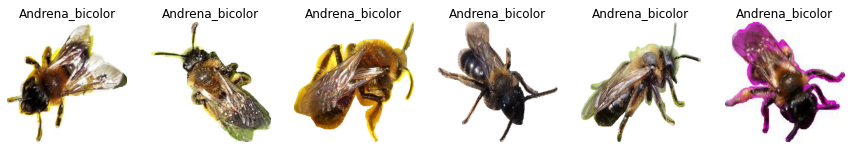

In [10]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = min(6, batch_size)
with tf.device('/CPU:0'):
    for images, labels in train_val_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[i])
            plt.title(classes[labels[i].numpy()])
            plt.axis("off")
plt.show()

In [11]:
for image_batch, labels_batch in train_val_set.take(1):
    print(image_batch.shape)
    print(labels_batch[0])

(64, 224, 224, 3)
tf.Tensor(0, shape=(), dtype=uint8)


2024-03-14 19:46:18.163204: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


### Load random images from broden

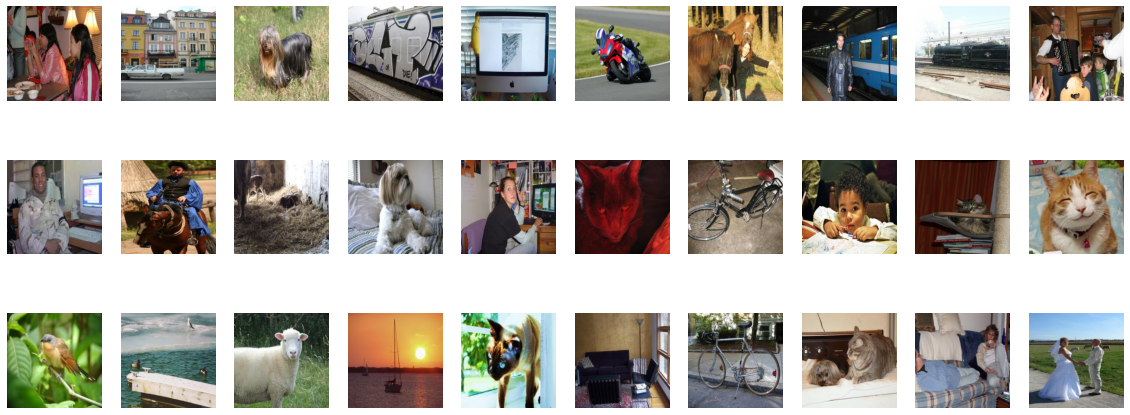

In [12]:
random_img_folder = '../data/broden1_224/images/pascal/'
input_size = img_height

random_imgs = os.listdir(random_img_folder)
random_imgs_filter = lambda f : all([rm not in f for rm in ['object', 'color', 'part']]) # only take 'natural' image

# Load same random images used for tcav fungi
with open('./beexplainable/metafiles/Fungi/raw/fungi_tcav_random.pickle', 'rb') as handle:
    files = pickle.load(handle)

random_dataset = [cv2.imread(random_img_folder+img)[...,::-1] for img in files]
random_dataset = [tf.image.resize(img, [img_width, img_height]) for img in random_dataset]
random_dataset = np.array([img/255.0 for img in random_dataset])

plt.figure(figsize = (20, 8))
for i in range(30):
    plt.subplot(3, 10, i+1)
    plt.imshow(random_dataset[i])
    plt.axis('off')

### Load Prototype Images

In [13]:
concepts_folder = CONCEPTS_PATH

concepts_files = os.listdir(concepts_folder)
concepts_availables = np.unique([t for t in concepts_files])
print('The available concepts are : \n', '; '.join(concepts_availables))

def load_concepts(concepts):
    files = glob.glob(CONCEPTS_PATH + concepts + '/*.jpg')
    imgs  = [cv2.imread(img)[...,::-1] for img in files]
    imgs  = [tf.image.resize(img, [img_width, img_height]) for img in imgs]
    imgs = [img/255.0 for img in imgs]

    return np.array(imgs)

The available concepts are : 
 fuzzy_dark_orange; fuzzy_yellow_black_stripes; smooth_shiny_dark_brown




Texture: fuzzy_dark_orange  - shape: (30, 224, 224, 3)


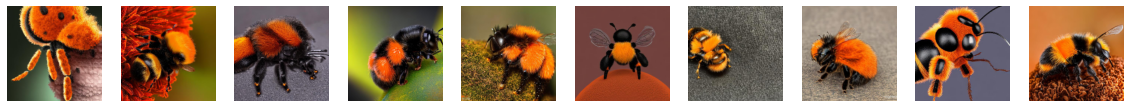



Texture: fuzzy_yellow_black_stripes  - shape: (30, 224, 224, 3)


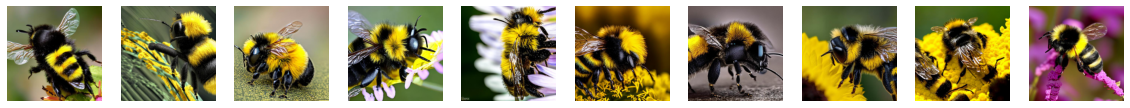



Texture: smooth_shiny_dark_brown  - shape: (30, 224, 224, 3)


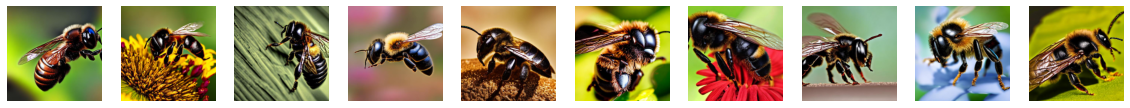

In [14]:
concepts = {concepts: load_concepts(concepts) for concepts in concepts_availables}

plt.rcParams["figure.figsize"] = [20, 8]
for concepts_name, images in concepts.items():
    print(f"\n\nTexture: {concepts_name}  - shape: {images.shape}")
    for i in range(10):
        plt.subplot(1, 10, i+1)
        plt.imshow(images[i])
        plt.axis('off')
    plt.show()

Mapping relevant concepts to true class labels

In [15]:
# One-hot-encode the concepts
concept_basis = OneHotEncoder().fit_transform([[0], [1], [2]]).toarray()
# A. bicolor:  orange + brown | B. lucorum:  yellow
# A. flavipes: brown          | B. pratorum: orange + yellow
# A. fulva:    orange
lookup_cls_concepts = [concept_basis[0] + concept_basis[2],
                       concept_basis[2],
                       concept_basis[0],
                       concept_basis[1],
                       concept_basis[0] + concept_basis[1]]
lookup_cls_concepts[0]

array([1., 0., 1.])

### Load Model

In [16]:
# Define initial training and other model parameters
epochs, drop_rate = 10, 0.5
lr, reg = 1e-3, 1e-3 # parameters optimized in HPO notebook
in_shape = (img_width, img_height, 3)

constructor, out_shape =  wm.build_simple_classifier, len(lookup_cls_concepts)
loss = 'sparse_categorical_crossentropy'
metrics = ['accuracy']

# Define whether to load fine grained backbone weights
load_pretrained_backbone = True # if False, ImageNet weights are loaded
# ResNet50 weights trained on iNat2021
# https://github.com/visipedia/newt/tree/main/benchmark
pretrained_weights_file = MODELS_PATH + 'backbones/resnet50_simclr_v1_inat20_no_top_500.h5' if load_pretrained_backbone else None

# Derive model name
input_form = 'masked_bbox' # raw, masked, bbox, masked_bbox
init = 'iNat' if load_pretrained_backbone else 'Imagenet'
model_name = 'ResNet50_' + init + '_' + input_form + '_5spec_2'

# The pretrained ResNet on iNat already has a GlobalAvgPooling layer
add_global_avg = False if load_pretrained_backbone else True

# Whether to retrain the backbone or not
trainable = True

In [17]:
# Build and compile
tf.keras.backend.clear_session()
cnn_name = 'CNN_Blocks_' + model_name

cnn = cls.CNN_ResNet50(in_shape, drop_rate, add_global_avg = add_global_avg, trainable = trainable,
                       weights_file = pretrained_weights_file, name = cnn_name)

model = constructor(in_shape, out_shape, cnn, reg,
                    input_name = 'jpg', model_name = model_name)

model.load_weights(MODELS_PATH + 'all/' + spec_subfolder + model_name + '/' + model_name + '.h5',
                   by_name = True, skip_mismatch = True)

model.compile(tf.keras.optimizers.Adam(lr), loss = loss, metrics = metrics)

### Weight Vectors

The class weight vectors are the corresponding weight vectors in the Dense layer.

For the prototypes/concepts, each weight vector is found through logistic regression between the prototype/concept images (positive samples) and random images from the broden dataset (negatives) in the latent space.

In [18]:
# Get (single) Dense layer responsible for predicting all classes
dense_layer = model.get_layer('dense_species')
dense_layer_weights = dense_layer.trainable_weights[0].numpy() # weights at position 0, bias term at position 1
np.shape(dense_layer_weights)

(2048, 5)

In [19]:
# Note: weight vectors are already almost unity vectors
cls_weights = {}
for id, cls in enumerate(classes):
    cls_weights[cls] = dense_layer_weights.T[id] #/ np.linalg.norm(dense_layer_weights.T[id], 2)
np.shape(cls_weights['Andrena_bicolor'])

(2048,)

#### Compute weight vectors for every prototype set

In [20]:
# Extract features from random dataset (there are 1000 random samples)
random_features = cnn(random_dataset)
np.shape(random_features)

2024-03-14 19:46:26.518747: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8401
2024-03-14 19:46:27.024529: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-03-14 19:46:27.025468: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-03-14 19:46:27.025528: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2024-03-14 19:46:27.026689: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-03-14 19:46:27.026787: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


TensorShape([1000, 2048])

In [21]:
# Compute prototype features in latent space (each prototype set has 30 vectors of dimension 2048)
con_features = {}
for con_name, con_imgs in concepts.items():
    con_features[con_name] = cnn(con_imgs)
np.shape(con_features['fuzzy_dark_orange'])

TensorShape([30, 2048])

In [22]:
# Compute prototype weight vectors via Logistic Regression for multiple partitions of the random set
# For every prototype set, we fit a logistic regressor to recognize the positive samples (the prototype vectors)
# against the negative samples (the random vectors)
num_parts = 30 # how often to randomly select subsets of the random set
con_weights = {}
for i in range(num_parts):
    # Select random indexes (starting after last concept img index)
    random_ids = np.random.choice( len(random_features), 500, replace = False )

    for con_name, con_f in con_features.items():

        # Build dataset of latent features: concept features are the positive examples, random features are the negatives
        con_rand_set = np.concatenate((con_f, random_features.numpy()[random_ids]))
        con_rand_y = [1]*len(con_f) + [0]*len(random_ids)

        # Fit log. regressor
        clf = LogisticRegression(random_state=0).fit(con_rand_set, con_rand_y)

        # Store normalized centered weight vectors (as in paper, page 6)
        if i == 0: con_weights[con_name] = []
        clf_centered = clf.coef_[0] - np.mean(clf.coef_[0])
        clf_norm = clf_centered / np.linalg.norm(clf_centered)
        con_weights[con_name].append( clf_norm )

np.shape(con_weights['fuzzy_dark_orange'])

(30, 2048)

#### Get global prototype relevance scores via projections of the class weight vectors on the prototype basis

In [23]:
# Get the list of concepts (for ease of access later)
con_list = list(concepts.keys())

In [24]:
# Build matrix of class weight vectors
# Each row is the weight vector of the Dense layer corresponding to that class
cls_mat = np.asarray(list(cls_weights.values()))
np.shape(cls_mat)

(5, 2048)

In [25]:
# Build matrix of prototype weight vectors
# Each row is a matrix of the weight vectors resulted from log. regressions for that row's concept
con_tensor = np.asarray(list(con_weights.values()))
np.shape(con_tensor)

(3, 30, 2048)

In [26]:
# Solve Least Squares to find optimal concept scores for every class
# Row i holds the mean relevance scores of class i w.r.t. all the concepts
cls_con_proj = []
for j in range(con_tensor.shape[1]):
    cls_con_proj.append( np.dot(cls_mat, np.linalg.pinv(con_tensor[:,j,:])) )
cls_con_proj = np.mean(cls_con_proj, axis=0) # average out over all the weight vectors of a concept
np.shape(cls_con_proj)

(5, 3)

In [27]:
# Print out mean concept relevance scores
for i in range(len(classes)):
    print(classes[i])
    for j in range(len(con_list)):
        print(con_list[j] + ': ' + str(cls_con_proj[i,j]))
    print()

Andrena_bicolor
fuzzy_dark_orange: -0.10024779913668466
fuzzy_yellow_black_stripes: -0.21018059712144682
smooth_shiny_dark_brown: 0.3192582899546317

Andrena_flavipes
fuzzy_dark_orange: -0.10000963800207631
fuzzy_yellow_black_stripes: -0.2338579714373859
smooth_shiny_dark_brown: 0.19072470972940597

Andrena_fulva
fuzzy_dark_orange: 0.1412719946903818
fuzzy_yellow_black_stripes: -0.31227910221234545
smooth_shiny_dark_brown: 0.023314008734442063

Bombus_lucorum
fuzzy_dark_orange: 0.12274228891599517
fuzzy_yellow_black_stripes: 0.16973642604553357
smooth_shiny_dark_brown: -0.2259275555430264

Bombus_pratorum
fuzzy_dark_orange: -0.011705315443532505
fuzzy_yellow_black_stripes: 0.31517002261170074
smooth_shiny_dark_brown: -0.2644449526511296



In [28]:
# Replace negative scores (that mark irrelevance of that concept) with 0's
cls_con_proj_pos = np.max((cls_con_proj, np.zeros(cls_con_proj.shape)), axis=0)
cls_con_proj_pos

array([[0.        , 0.        , 0.31925829],
       [0.        , 0.        , 0.19072471],
       [0.14127199, 0.        , 0.02331401],
       [0.12274229, 0.16973643, 0.        ],
       [0.        , 0.31517002, 0.        ]])

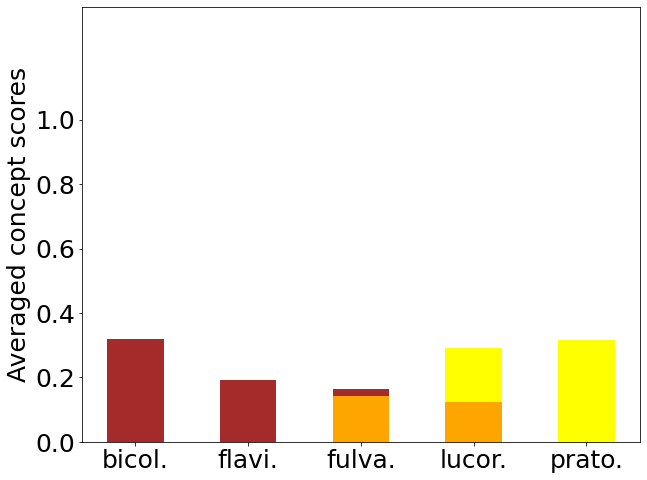

In [29]:
con_colors = ['orange', 'yellow', 'brown']
fontsize = 25
width=0.5
fig, ax = plt.subplots(figsize=(10,8))
bottom = np.zeros(len(classes))
for j in range(cls_con_proj_pos.shape[1]):
    rects = plt.bar(classes, cls_con_proj_pos[:,j], width=0.5, label=con_list[j], bottom=bottom, color=con_colors[j])
    bottom += cls_con_proj_pos[:,j]

# Add asterisks for zero-height bars
for rect, b in zip(rects, bottom):
   if b == 0:
       ax.text(rect.get_x() + rect.get_width() / 2,
               0.01,  # Adjust vertical position slightly
               '$\diamond$', ha='center', va='bottom', fontsize=fontsize+10, color='black')

plt.ylim(0.0, 1.35)
plt.xticks(np.arange(0.0, 10*width, width*2),
           [c.split('_')[1][:5]+'.' for c in classes],
           fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylabel('Averaged concept scores', fontsize=fontsize)
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/mean_bees_ibd_stacked.png', bbox_inches='tight')
plt.show()

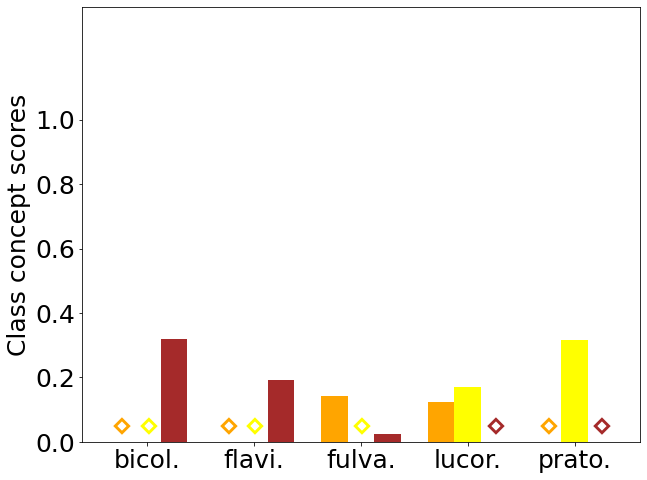

In [30]:
x = np.arange(len(classes))  # the label locations
width = 0.25  # the width of the bars
multiplier = 0
fontsize = 25
con_colors = ['orange', 'yellow', 'brown']

fig, ax = plt.subplots(figsize=(10, 8))  # Create axes for text placement
for i in range(len(cls_con_proj_pos.T)):
   offset = width * multiplier
   rects = plt.bar(x + offset, cls_con_proj_pos[:,i], width, label=con_list[i], color=con_colors[i])
   multiplier += 1

   # Add asterisks for zero-height bars
   for rect, height in zip(rects, cls_con_proj_pos[:,i]):
       if height < 1e-3:
           ax.text(rect.get_x() + rect.get_width() / 2,
                   height,  # Adjust vertical position slightly
                   '$\diamond$', ha='center', va='bottom', fontsize=fontsize+10, color=con_colors[i])

plt.xticks(x+width,
           [c.split('_')[1][:5]+'.' for c in classes],
           fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylim(0.0, 1.35)
plt.ylabel('Class concept scores', fontsize=fontsize)
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/mean_bees_ibd_scores.png', bbox_inches='tight')
plt.show()

#### Get local concept relevance scores via projections of each sample vector on the concept basis

In [31]:
# One-hot-encode the concepts
concept_basis = OneHotEncoder().fit_transform([[0], [1], [2]]).toarray()
# A. bicolor:  orange + brown | B. lucorum:  yellow
# A. flavipes: brown          | B. pratorum: orange + yellow
# A. fulva:    orange
lookup_cls_concepts = [concept_basis[0] + concept_basis[2],
                       concept_basis[2],
                       concept_basis[0],
                       concept_basis[1],
                       concept_basis[0] + concept_basis[1]]
lookup_cls_concepts[0]

array([1., 0., 1.])

In [32]:
# Extract features for whole test set
cnn_model = tf.keras.Model(inputs=cnn.input, outputs=cnn.output)
test_features = cnn_model.predict(train_val_set, verbose=1)
test_features.shape

4/4 [==============================] - 3s 327ms/step


(216, 2048)

In [33]:
# Store predictions before Softmax layer (needed for normalizing scores to true probabilities)
model_no_soft = tf.keras.Model(inputs=model.input, outputs=model.get_layer('dense_species').output)
preds_no_soft = model_no_soft.predict(train_val_set, verbose=1)
preds_no_soft.shape

4/4 [==============================] - 1s 58ms/step


(216, 5)

In [34]:
# Project every test vector onto the prototype matrix
# Row i holds the mean relevance scores of the i-th test sample w.r.t. all the prototypes
test_con_proj = []
for j in range(con_tensor.shape[1]):
    test_con_proj.append( np.dot(test_features, con_tensor[:,j,:].T) )
test_con_proj = np.mean(test_con_proj, axis=0) # average out over all the weight vectors of a concept
np.shape(test_con_proj)

(216, 3)

In [35]:
probs_cls_dict = {}
test_con_proj_cls_avg = []
for c in range(len(classes)):
    test_con_proj_cls = test_con_proj[np.where(y_true_bees == c)]
    preds_no_soft_cls = preds_no_soft[np.where(y_true_bees == c), c][0][0]

    # Get true concept(s) based on true class
    true_con = lookup_cls_concepts[c]

    # Concept scores for class c
    s = cls_con_proj_pos[c]

    # Average sample scores divided by w.T*a (Equation 7, page 6)
    test_con_proj_cls_avg.append( np.mean(test_con_proj_cls * s / preds_no_soft_cls, axis=0) )

    bce, cos_sim = [], []
    for p in test_con_proj_cls:
        # Compute binary cross entropy
        bce.append( log_loss(true_con, p*s) )
        # Compute cosine sim.
        cos_sim.append( cosine_similarity(true_con.reshape(1, -1), (p*s).reshape(1, -1))[0][0] )

    # Rank correlation
    rank = lrap(np.tile(true_con, (len(test_con_proj_cls),1)), test_con_proj_cls)

    print(classes[c])
    print('BCE:')
    print(str(np.round(np.mean(bce),4)) + '+/-' + str(np.round(np.std(bce),4)))
    print('Cosine Similarity:')
    print(str(np.round(np.mean(cos_sim),4)) + '+/-' + str(np.round(np.std(cos_sim),4)))
    print('Rank Correlation:')
    print(rank)
    print()

Andrena_bicolor
BCE:
12.2383+/-2.0181
Cosine Similarity:
0.66+/-0.2539
Rank Correlation:
0.9388888888888888

Andrena_flavipes
BCE:
2.3245+/-4.113
Cosine Similarity:
0.6667+/-0.7454
Rank Correlation:
0.9666666666666667

Andrena_fulva
BCE:
0.7556+/-2.0186
Cosine Similarity:
0.9247+/-0.3596
Rank Correlation:
0.961111111111111

Bombus_lucorum
BCE:
1.204+/-2.8988
Cosine Similarity:
0.7644+/-0.4016
Rank Correlation:
0.8975694444444445

Bombus_pratorum
BCE:
11.9568+/-2.0569
Cosine Similarity:
0.66+/-0.2539
Rank Correlation:
0.9888888888888888



In [37]:
# Replace scores slightly below 0 (due to rounding errors) with 0's
test_con_proj_cls_avg = np.asarray(test_con_proj_cls_avg)
test_con_proj_cls_avg_pos = np.max((test_con_proj_cls_avg, np.zeros(test_con_proj_cls_avg.shape)), axis=0)
test_con_proj_cls_avg_pos

array([[0.        , 0.        , 0.10071995],
       [0.        , 0.        , 0.01384604],
       [0.02083454, 0.        , 0.        ],
       [0.01760055, 0.03627799, 0.        ],
       [0.        , 0.10405466, 0.        ]])

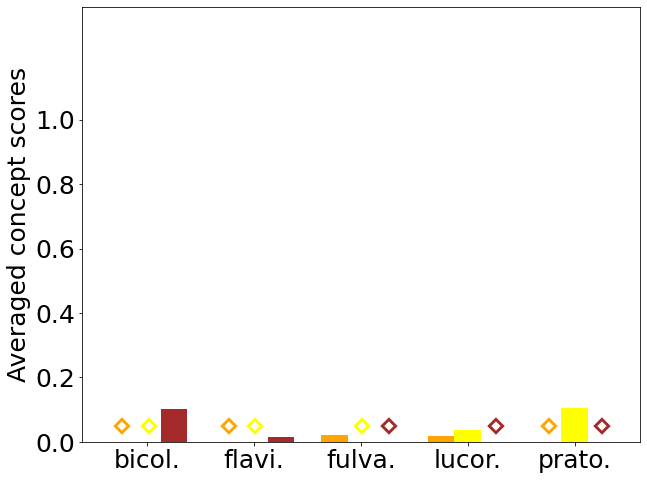

In [39]:
x = np.arange(len(classes))  # the label locations
width = 0.25  # the width of the bars
multiplier = 0
fontsize = 25
con_colors = ['orange', 'yellow', 'brown']

fig, ax = plt.subplots(figsize=(10, 8))  # Create axes for text placement
for i in range(len(test_con_proj_cls_avg_pos.T)):
   offset = width * multiplier
   rects = plt.bar(x + offset, test_con_proj_cls_avg_pos[:,i], width, label=con_list[i], color=con_colors[i])
   multiplier += 1

   # Add asterisks for zero-height bars
   for rect, height in zip(rects, test_con_proj_cls_avg_pos[:,i]):
       if height < 1e-3:
           ax.text(rect.get_x() + rect.get_width() / 2,
                   height,  # Adjust vertical position slightly
                   '$\diamond$', ha='center', va='bottom', fontsize=fontsize+10, color=con_colors[i])

plt.xticks(x+width,
           [c.split('_')[1][:5]+'.' for c in classes],
           fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylim(0.0, 1.35)
plt.ylabel('Averaged concept scores', fontsize=fontsize)
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/mean_bees_ibd.png', bbox_inches='tight')
plt.show()

In [40]:
# Count how often each prototype was found as most relevant for each class
cls_con_freq = {}
for i in range(len(classes)):
    rel_con_inds = np.argmax(test_con_proj[np.where(y_true_bees == i)], axis=1)
    freq = np.asarray([np.count_nonzero(rel_con_inds == j) for j in range(len(con_list))]) / len(rel_con_inds)
    cls_con_freq[classes[i]] = freq
cls_con_freq

{'Andrena_bicolor': array([0.2       , 0.06666667, 0.73333333]),
 'Andrena_flavipes': array([0.        , 0.06666667, 0.93333333]),
 'Andrena_fulva': array([0.93333333, 0.        , 0.06666667]),
 'Bombus_lucorum': array([0.17708333, 0.80208333, 0.02083333]),
 'Bombus_pratorum': array([0.06666667, 0.93333333, 0.        ])}

In [41]:
# Invert dictionary (for plotting purposes)
con_cls_freq = {}
for c in con_list:
    con_cls_freq[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        con_cls_freq[c][i] = cls_con_freq[classes[i]][con_list.index(c)]
con_cls_freq

{'fuzzy_dark_orange': array([0.2       , 0.        , 0.93333333, 0.17708333, 0.06666667]),
 'fuzzy_yellow_black_stripes': array([0.06666667, 0.06666667, 0.        , 0.80208333, 0.93333333]),
 'smooth_shiny_dark_brown': array([0.73333333, 0.93333333, 0.06666667, 0.02083333, 0.        ])}

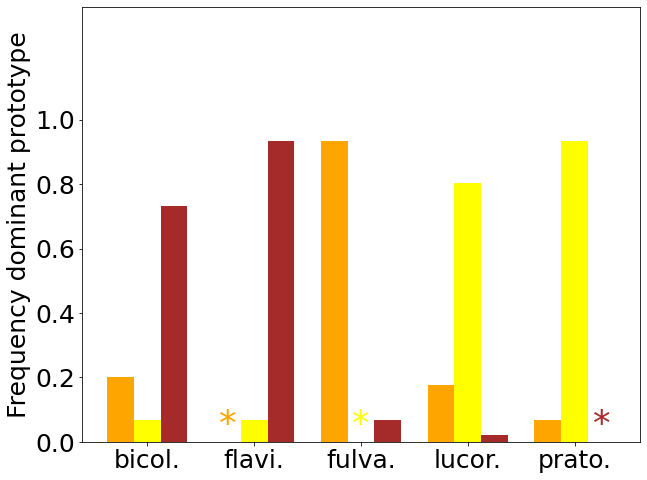

In [42]:
x = np.arange(len(classes))  # the label locations
width = 0.25  # the width of the bars
multiplier = 0
fontsize = 25
con_colors = ['orange', 'yellow', 'brown']

fig, ax = plt.subplots(figsize=(10, 8))  # Create axes for text placement
for i, (con, freq) in enumerate(con_cls_freq.items()):
   offset = width * multiplier
   rects = plt.bar(x + offset, freq, width, label=con, color=con_colors[i])
   multiplier += 1

   # Add asterisks for zero-height bars
   for rect, height in zip(rects, freq):
       if height == 0:
           ax.text(rect.get_x() + rect.get_width() / 2,
                   height,  # Adjust vertical position slightly
                   '*', ha='center', va='bottom', fontsize=fontsize+10, color=con_colors[i])

plt.xticks(x + width, classes, fontsize=fontsize)
plt.xticks(x+width,
           [c.split('_')[1][:5]+'.' for c in classes],
           fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylabel('Frequency dominant prototype', fontsize=fontsize)
plt.ylim(0.0, 1.35)
#plt.legend([c[:-4] for c in concepts], loc='upper right',
#           fontsize=fontsize, ncol=3, bbox_to_anchor=(1, 1))
#plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/bees_ibd_freq.png', bbox_inches='tight')
plt.show()